<center><h1>Xia_Iris_HW6</h1></center>

Name: Iris Xia
<br>
Github Username: xd11997
<br>
USC ID: 1152659547

## 1. Tree-Based Methods

Import packages

In [21]:
%pip install imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn][imbalanced-learn]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

### (a) Download the APS Failure data

In [4]:
data_dir = Path("Data")

train_path = data_dir / "aps_failure_training_set.csv"
test_path = data_dir / "aps_failure_test_set.csv"

train = pd.read_csv(train_path, skiprows=20, na_values=["na"])
test = pd.read_csv(test_path, skiprows=20, na_values=["na"])

print("Training set:", train.shape)
print("Test set:", test.shape)
print(train.head())


Training set: (60000, 171)
Test set: (16000, 171)
  class  aa_000  ab_000        ac_000  ad_000  ae_000  af_000  ag_000  ag_001  \
0   neg   76698     NaN  2.130706e+09   280.0     0.0     0.0     0.0     0.0   
1   neg   33058     NaN  0.000000e+00     NaN     0.0     0.0     0.0     0.0   
2   neg   41040     NaN  2.280000e+02   100.0     0.0     0.0     0.0     0.0   
3   neg      12     0.0  7.000000e+01    66.0     0.0    10.0     0.0     0.0   
4   neg   60874     NaN  1.368000e+03   458.0     0.0     0.0     0.0     0.0   

   ag_002  ...     ee_002    ee_003    ee_004    ee_005    ee_006    ee_007  \
0     0.0  ...  1240520.0  493384.0  721044.0  469792.0  339156.0  157956.0   
1     0.0  ...   421400.0  178064.0  293306.0  245416.0  133654.0   81140.0   
2     0.0  ...   277378.0  159812.0  423992.0  409564.0  320746.0  158022.0   
3     0.0  ...      240.0      46.0      58.0      44.0      10.0       0.0   
4     0.0  ...   622012.0  229790.0  405298.0  347188.0  286954.0  3

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for handling missing values include deleting incomplete rows or columns, using simple imputation (such as the mean, median, or mode), and using model-based methods such as KNN or multiple imputation. I use median imputation because the features are numeric and the median is less sensitive to outliers than the mean.

In [6]:
X_train = train.drop(columns="class")
X_test = test.drop(columns="class")

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

#### (ii) Calculate the coefficient of variation

In [7]:
cv = X_train.std(ddof=1) / X_train.mean()
cv = cv.replace([float("inf"), -float("inf")], float("nan"))

cv

aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

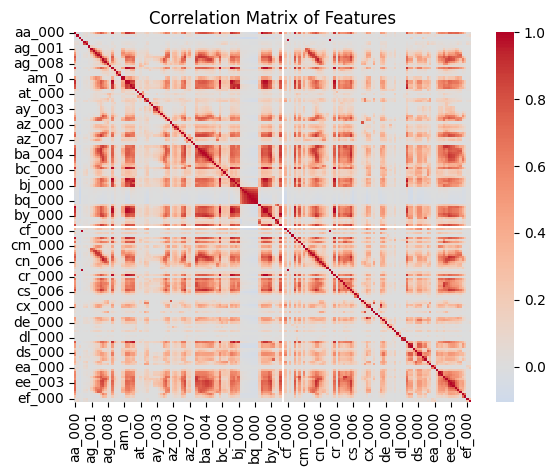

In [8]:
corr_matrix = X_train.corr()

sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Features")
plt.show()

The correlation matrix shows that some groups of features are strongly positively correlated, while many other feature pairs have weak correlations.

#### (iv) Make scatter plots and box plots

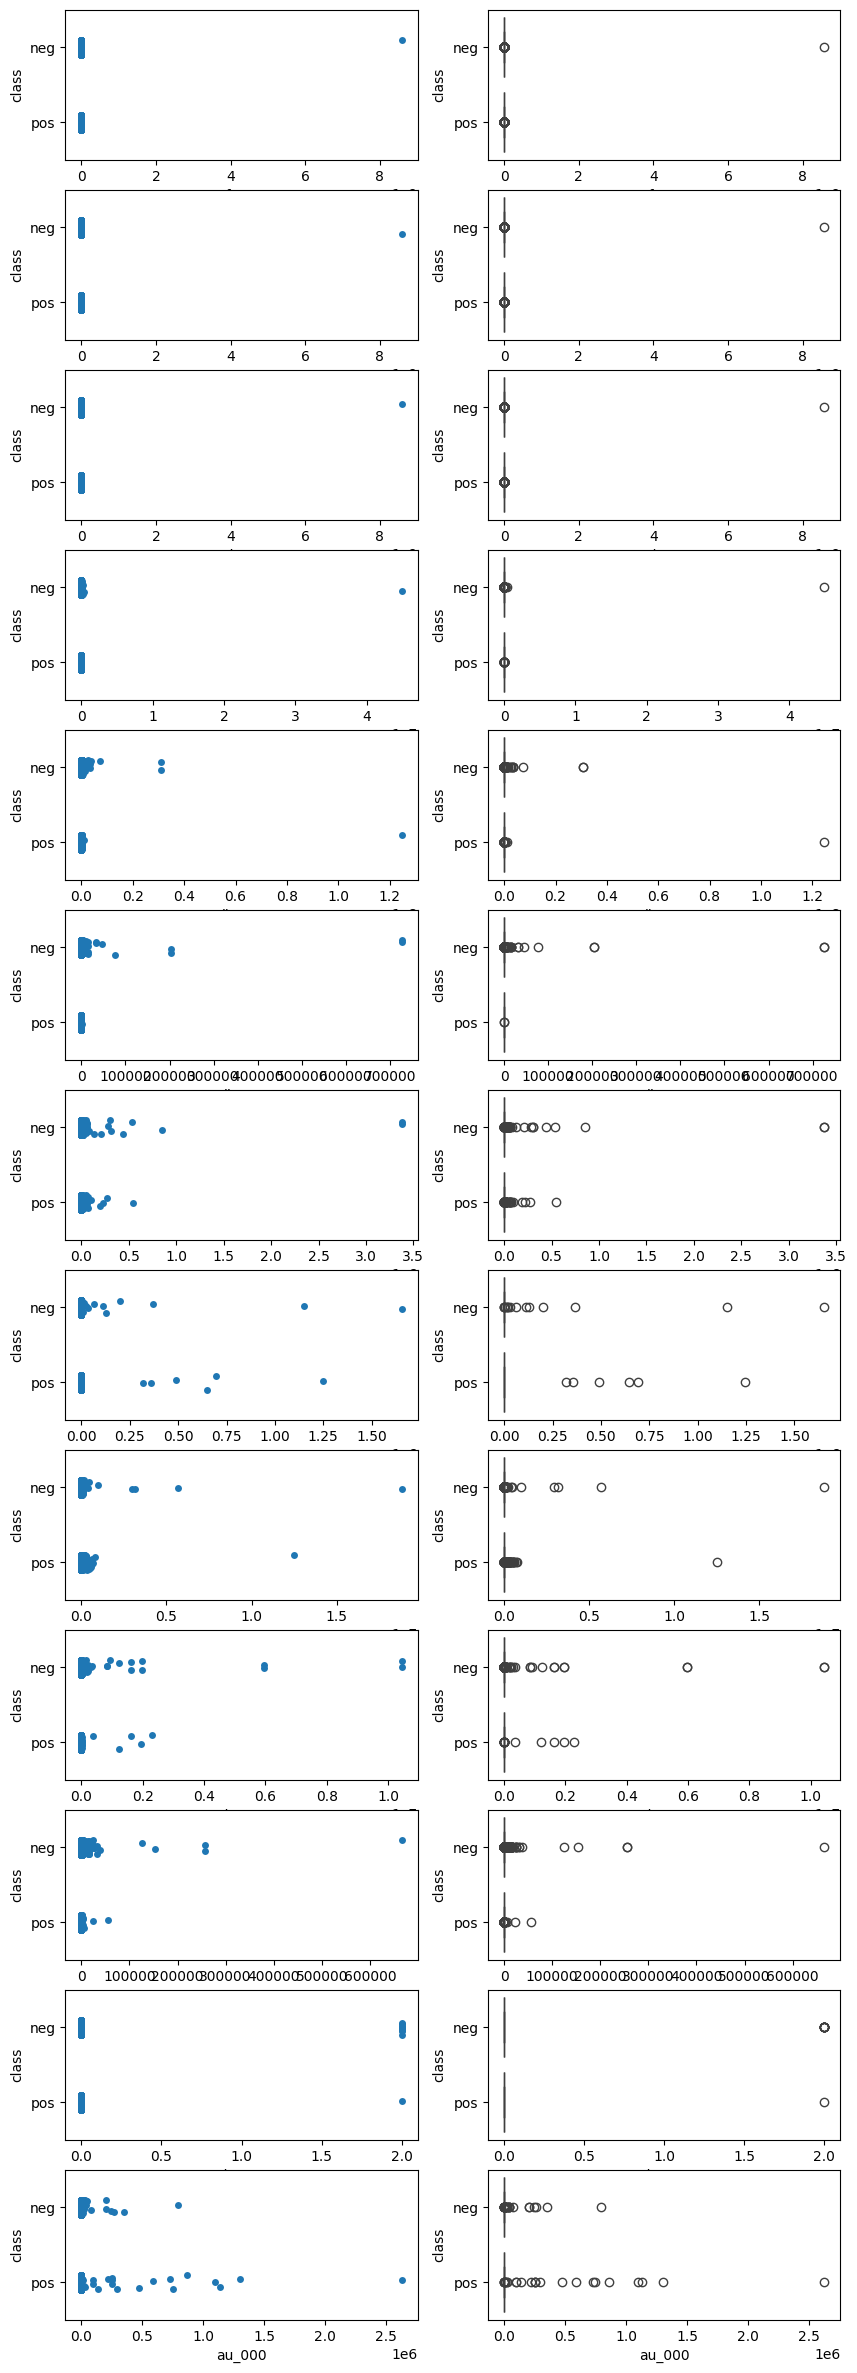

In [10]:
top_features = cv.nlargest(13).index
fig, axes = plt.subplots(13, 2, figsize=(10, 30))

for i, feature in enumerate(top_features):
    sns.stripplot(x=X_train[feature], y=train["class"], ax=axes[i, 0])
    sns.boxplot(x=X_train[feature], y=train["class"], ax=axes[i, 1])

#### (v) Is this data set imbalanced?

In [11]:
train["class"].value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

The dataset is seriously imbalanced. This imbalance can lead to biased model performance, where the model may predict the majority class more often than the minority class. 

### (c) Train a random forest

In [13]:
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})

rf = RandomForestClassifier(
    n_estimators=100, oob_score=True, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

for name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pred = rf.predict(X)
    prob = rf.predict_proba(X)[:, 1]
    print(name)
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("Misclassification rate:", np.mean(pred != y))
    print("AUC:", roc_auc_score(y, prob))

print("OOB error:", 1 - rf.oob_score_)


Train
Confusion matrix:
 [[59000     0]
 [    1   999]]
Misclassification rate: 1.6666666666666667e-05
AUC: 1.0
Test
Confusion matrix:
 [[15610    15]
 [  106   269]]
Misclassification rate: 0.0075625
AUC: 0.992754432
OOB error: 0.006116666666666659


The random forest achieved a low test misclassification rate (0.76%) and a high AUC (0.993), but it still missed 28.3% of positive cases.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be addressed through class weighting or resampling. Here, I use balanced_subsample, which assigns inverse-frequency weights to classes in each bootstrap sample, giving greater influence to the minority class.

In [14]:
rf_balanced = RandomForestClassifier(
    n_estimators=100, oob_score=True, random_state=42,
    n_jobs=-1, class_weight="balanced_subsample"
)
rf_balanced.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [15]:
for name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pred = rf_balanced.predict(X)
    prob = rf_balanced.predict_proba(X)[:, 1]
    print(name)
    print("Confusion matrix:\n", confusion_matrix(y, pred))
    print("Misclassification rate:", np.mean(pred != y))
    print("AUC:", roc_auc_score(y, prob))

print("OOB error:", 1 - rf_balanced.oob_score_)


Train
Confusion matrix:
 [[59000     0]
 [    1   999]]
Misclassification rate: 1.6666666666666667e-05
AUC: 1.0
Test
Confusion matrix:
 [[15609    16]
 [  156   219]]
Misclassification rate: 0.01075
AUC: 0.990458112
OOB error: 0.007883333333333353


The class-weighted random forest performed slightly worse than the uncompensated model, with a higher test misclassification rate, a lower AUC, and lower recall for the positive class.

### (e) XGBoost and Model Trees

In [17]:
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

search = GridSearchCV(
    xgb,
    {"reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

search.fit(X_train, y_train)
print("Best alpha:", search.best_params_)
print("CV error:", 1 - search.best_score_)

Best alpha: {'reg_alpha': 0.01}
CV error: 0.006349999999999967


In [18]:
xgb_best = search.best_estimator_

for name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pred = xgb_best.predict(X)
    prob = xgb_best.predict_proba(X)[:, 1]
    print(name)
    print(confusion_matrix(y, pred))
    print("Misclassification rate:", np.mean(pred != y))
    print("AUC:", roc_auc_score(y, prob))

Train
[[59000     0]
 [    1   999]]
Misclassification rate: 1.6666666666666667e-05
AUC: 0.999999372881356
Test
[[15599    26]
 [   87   288]]
Misclassification rate: 0.0070625
AUC: 0.9939749546666666


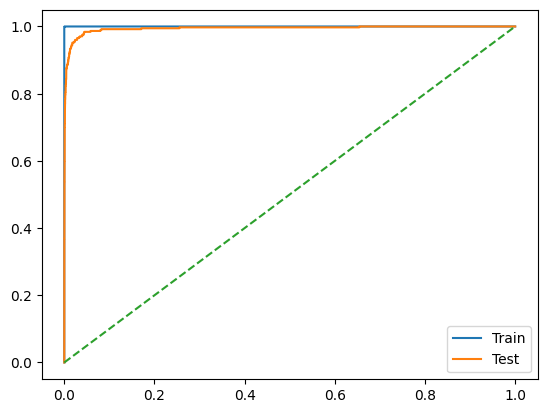

In [19]:
for name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    fpr, tpr, _ = roc_curve(y, xgb_best.predict_proba(X)[:, 1])
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "--")
plt.legend()
plt.show()

With \(\alpha=0.01\) selected by 5-fold cross-validation, the XGBoost model achieved a CV error of 0.635%, a test misclassification rate of 0.706%, and a test AUC of 0.994.

### (f) Use SMOTE to pre-process your data

In [23]:
smote_xgb = Pipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        n_estimators=100, tree_method="hist", random_state=42, n_jobs=1
    ))
])

In [24]:
smote_search = GridSearchCV(
    smote_xgb,
    {"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

smote_search.fit(X_train, y_train)

print("Best alpha:", smote_search.best_params_)
print("CV error:", 1 - smote_search.best_score_)

Best alpha: {'xgb__reg_alpha': 0.01}
CV error: 0.0065833333333333854


Train
[[59000     0]
 [    1   999]]
Misclassification rate: 1.6666666666666667e-05
AUC: 0.9999945677966101
Test
[[15567    58]
 [   64   311]]
Misclassification rate: 0.007625
AUC: 0.9937776639999999


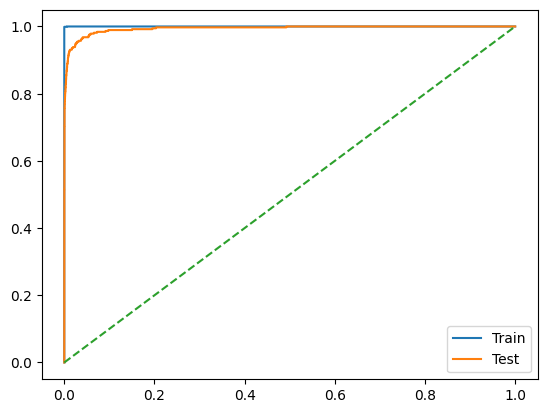

In [25]:
smote_model = smote_search.best_estimator_

for name, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pred = smote_model.predict(X)
    prob = smote_model.predict_proba(X)[:, 1]
    print(name)
    print(confusion_matrix(y, pred))
    print("Misclassification rate:", np.mean(pred != y))
    print("AUC:", roc_auc_score(y, prob))

    fpr, tpr, _ = roc_curve(y, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "--")
plt.legend()
plt.show()

Compared with the uncompensated model, SMOTE improved positive-class recall but increased false positives, resulting in a slightly higher test misclassification rate and a similar AUC.

## 2. ISLR 6.6.3

(a):
iv.  Steadily decrease --- As \(s\) increases, the constraint becomes less restrictive, so the training RSS cannot increase.

(b): ii. Decrease initially, and then eventually start increasing in a U shape --- Test RSS typically decreases at first and then increases as the model becomes more flexible and eventually overfits the data.

(c): (iii) Steadily increase. --- As \(s\) increases, the model becomes more flexible and its variance generally increases.

(d): (iv) Steadily decrease. --- As \(s\) increases, the model becomes more flexible, reducing its squared bias.

(e): (v) Remain constant. --- The irreducible error is determined by the inherent noise in the data, not by \(s\).

## 3. ISLR 6.6.5

(a) Since $\hat{\beta}_0=0$, the ridge optimization problem is

$$
\min_{\beta_1,\beta_2}
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+\lambda(\beta_1^2+\beta_2^2)
$$

Using the given conditions, let $x_{11}=x_{12}=a$ and $y_1=b$. Then $x_{21}=x_{22}=-a$ and $y_2=-b$, so the objective becomes

$$
\min_{\beta_1,\beta_2}
2\left[b-a(\beta_1+\beta_2)\right]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

(b) The RSS term depends only on beta_1 + beta_2. For a fixed sum S, beta_1^2 + beta_2^2 = (S^2 + (beta_1 - beta_2)^2) / 2, which is minimized when beta_1 = beta_2. Therefore, the ridge estimates satisfy beta_hat_1 = beta_hat_2.

(c) The lasso optimization problem is to minimize 2[b - a(beta_1 + beta_2)]^2, subject to |beta_1| + |beta_2| <= s, where a = x_11 = x_12 and b = y_1.

(d) Because x1 = x2, the fitted values depend only on T = beta_1 + beta_2. Let T* be the optimal sum. Any pair satisfying beta_1 + beta_2 = T* and |beta_1| + |beta_2| <= s gives the same optimal fit. For example, if T* > 0, any split with beta_1 between 0 and T* and beta_2 = T* - beta_1 is a solution, so there are infinitely many.

## 4. ISLR 8.4.5

For majority voting, 6 trees predict Red and 4 predict Green, so the final prediction is Red.

The average probability of Red is 0.45, which is below 0.5, so classifying by average probability gives Green.

## 5. ISLR 9.7.3

(a)

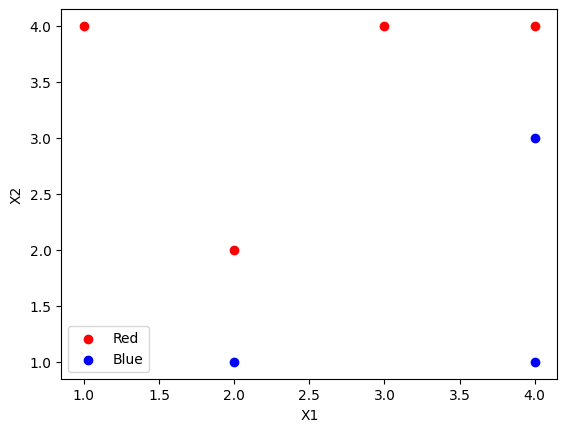

In [29]:
plt.scatter([3, 2, 4, 1], [4, 2, 4, 4], color="red", label="Red")
plt.scatter([2, 4, 4], [1, 3, 1], color="blue", label="Blue")

plt.xlabel("X1")
plt.ylabel("X2")
plt.legend()
plt.show()

(b) The optimal separating line is X2 = X1 - 0.5, or 1 - 2X1 + 2X2 = 0.

(c) Classify an observation as Red if 1 - 2X1 + 2X2 > 0, and Blue otherwise. Thus, beta_0 = 1, beta_1 = -2, and beta_2 = 2.

(d) The margin boundaries are X2 = X1 and X2 = X1 - 1. The support vectors are observations 2, 3, 5, and 6. The distance from the separating line to either boundary is about 0.354, and the full margin width is about 0.707.

(e) The support vectors are observations 2 and 3 (Red), and observations 5 and 6 (Blue).

(f) Observation 7 is not a support vector. A small movement that keeps it away from the margin will not change the maximal margin hyperplane.

(g) One non-optimal separating line is X2 = X1 - 0.25. Classify as Red above the line and Blue below it. It separates the observations but is not centered between the closest points of the two classes.

(h) Add a Blue observation at (2.5, 3). It lies inside the convex hull of the Red observations, so no hyperplane can separate the two classes.